In [42]:
import pickle
import sys

sys.path = [p for p in sys.path if "positron-python" not in p]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import confusion_matrix

import myutils


In [81]:
workspace,experiment=myutils.workspace()
save = True

In [ ]:
model_dir = experiment / "results/pred-with-fine-tuning" / 'pred_heroes-2026-10-25_172348' 
model_results = model_dir / 'results.pkl'
with open(model_results, 'rb') as f:
    model_results = pickle.load(f)
id2type = model_results['id_maps']


In [97]:
# run = "pred_scGPT_pancancer-2026-10-29_134407"
# run = 'pred_scGPT_pancancer-2026-10-29_125642'
run = "pred_scGPT_pancancer-2026-10-29_163749"

if run == "pred_scGPT_pancancer-2026-10-29_163749":
    id2type = {
    0 : "B/Plasma cells",
    1 : "Fibroblasts/Pericytes",
    2 : "Lymphoid cells",
    3 : "Myeloid cells",
    4 : "Endothelial cells",
    5 : "Tumor"
}
run_dir = experiment / f'results/pred-on-fine-tuned/{run}'
result_file = run_dir / 'results.pkl'
assert result_file.exists()
data_file = experiment / "data/heroes_pool8_scRNA_hvg.h5ad"
celltype_col = "consensus_celltype"
assert data_file.exists()

with open(result_file, 'rb') as f:
    results = pickle.load(f)
predictions = results['predictions']

adata = sc.read(data_file)
adata.obs["predictions"] = [id2type[int(p)] for p in predictions]
print(adata)
sum(adata.obs[celltype_col] == adata.obs['predictions'])

AnnData object with n_obs × n_vars = 8813 × 3000
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'consensus_celltype', 'predictions'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scvi_normalized', None (.X)


1236

In [98]:
sc.pl.umap(
        adata,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata.obs[celltype_col].cat.categories,
        adata.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

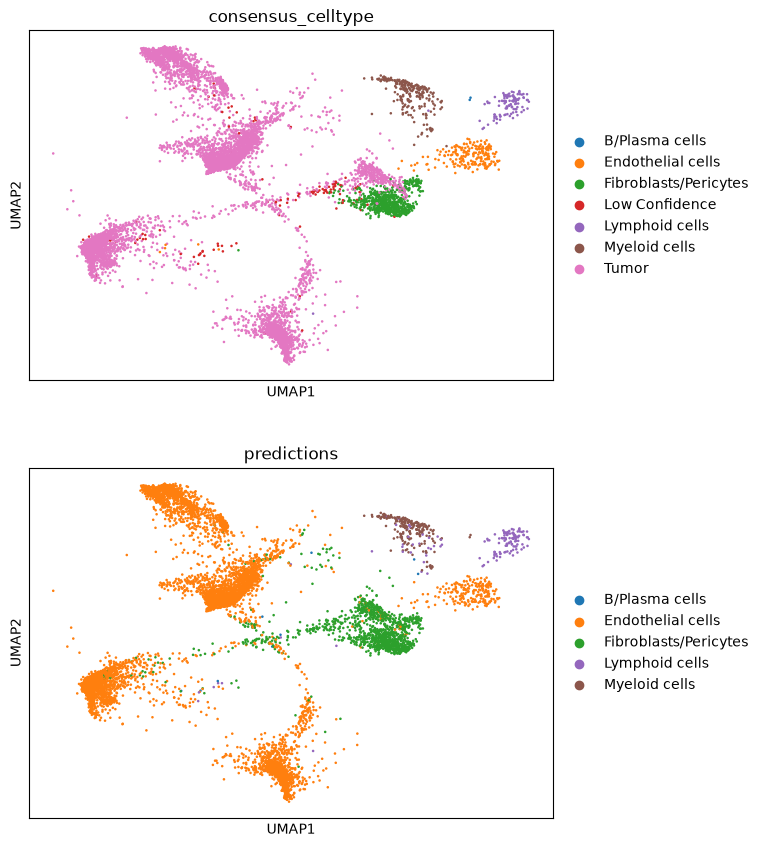

In [99]:
sc.pl.umap(
        adata,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
if save: plt.savefig(run_dir / "results.png", dpi=300, bbox_inches="tight")

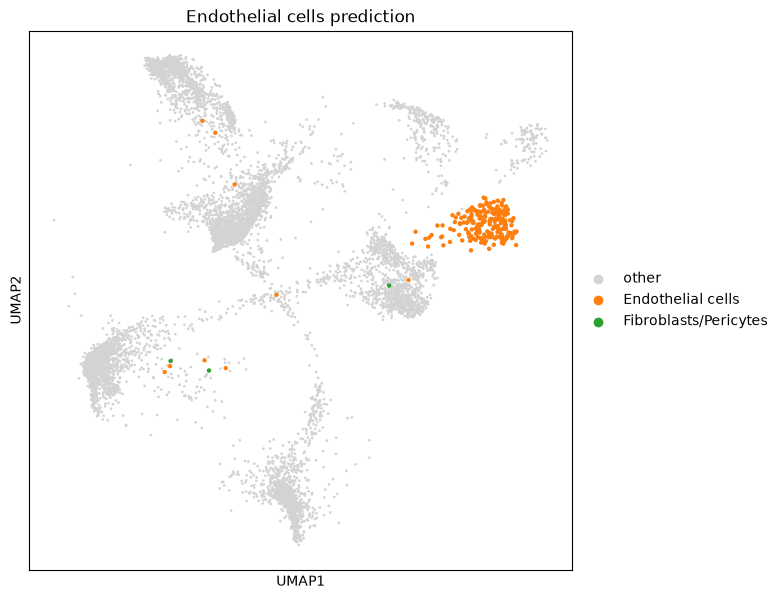

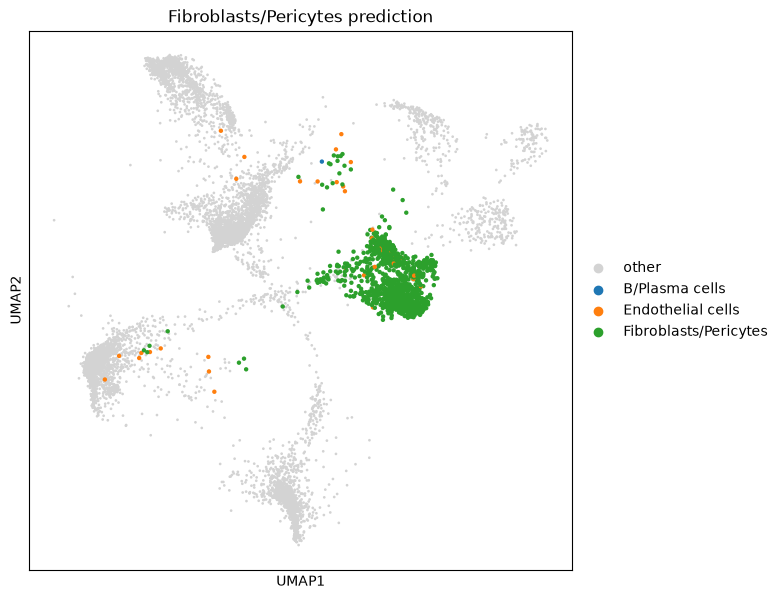

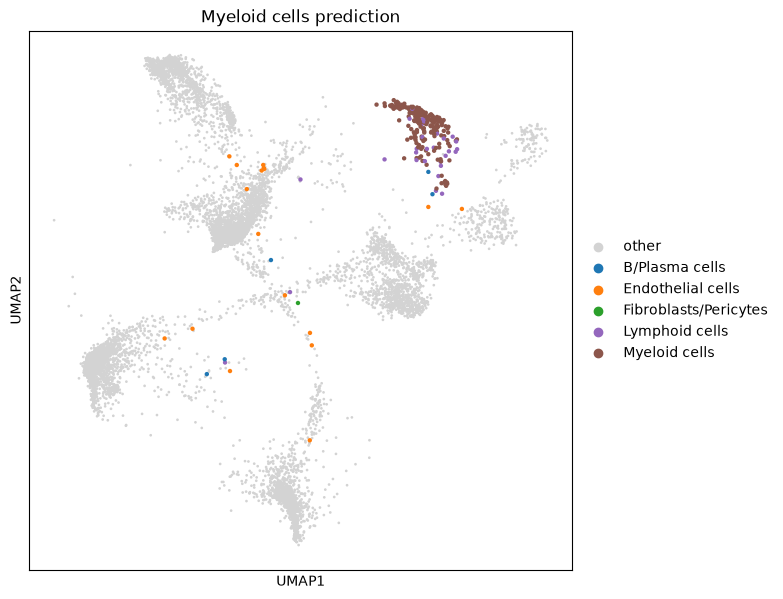

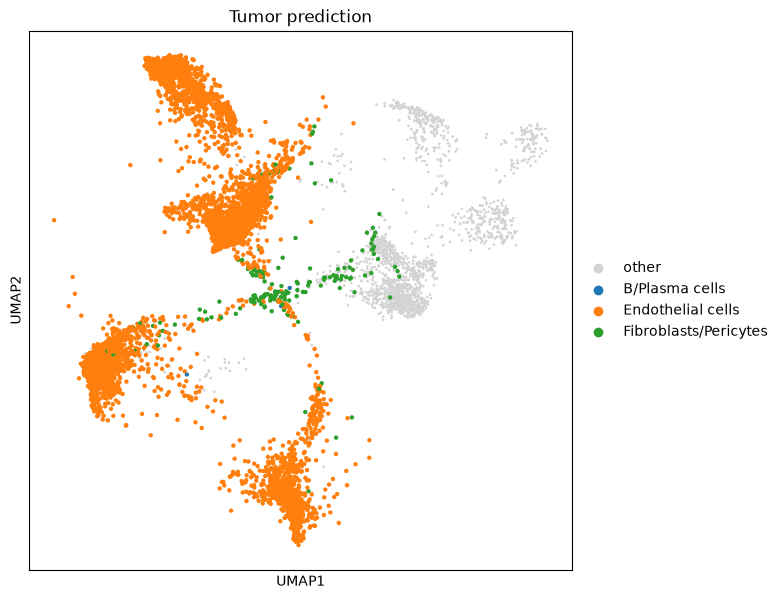

In [103]:
adata_plot = adata.copy()
for celltype in adata_plot.obs.consensus_celltype.cat.categories.to_list():
    myutils.inspect_prediction(adata_plot, celltype, palette=_palette, celltype_col="celltype", save_dir=run_dir)

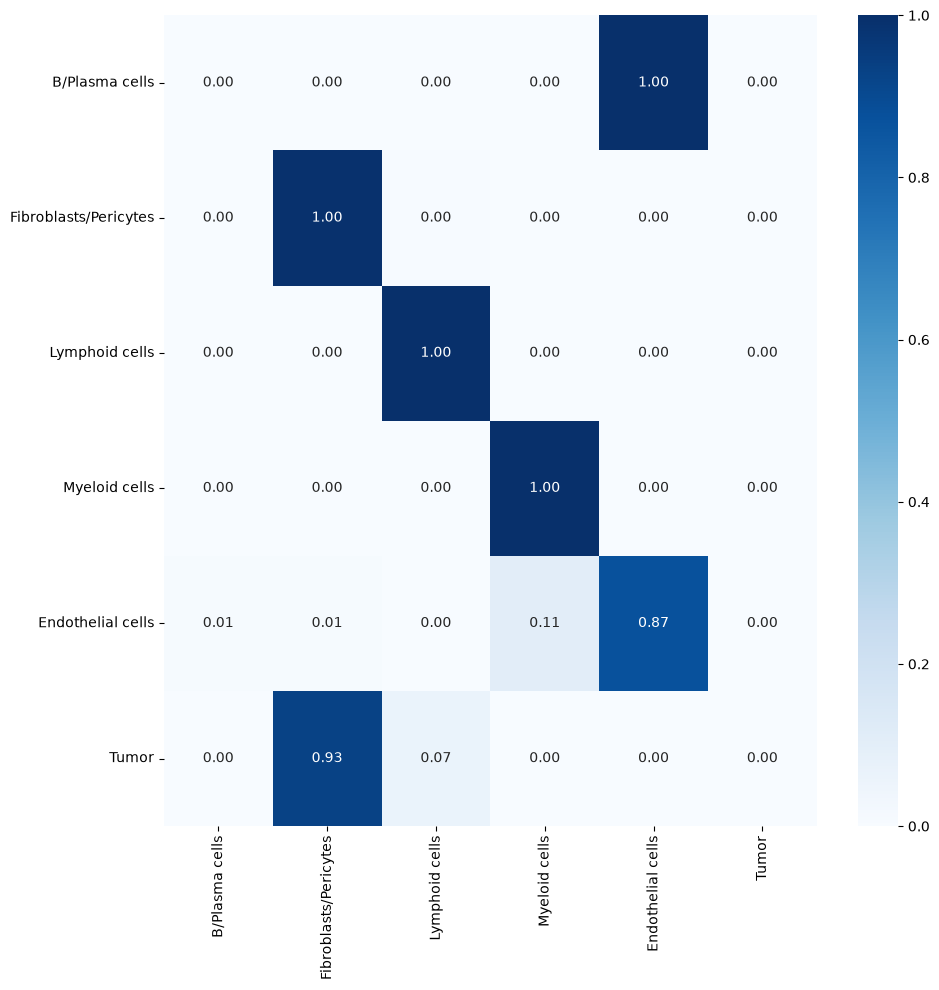

In [104]:
celltypes = [c for c in adata.obs[celltype_col].unique() if c in id2type.values()]
celltypes = [id2type[i] for i in range(len(celltypes))]
adata_wo_lowconf = adata[adata.obs.consensus_celltype != 'Low Confidence'].copy()
labels = adata_wo_lowconf.obs.consensus_celltype.tolist() 
predictions = adata_wo_lowconf.obs.predictions.tolist() 
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])
if save: cm.to_csv(run_dir/ 'confusion_matrix.csv')
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.yticks(rotation=0)
plt.tight_layout()
if save: plt.savefig(run_dir / "confusion_matrix.png", dpi=300, )

In [106]:
import os

model_dir = experiment / "results/pred-with-fine-tuning" / 'pred_heroes-2026-10-25_172348' 
model_results = model_dir / 'results.pkl'
data_file = experiment / "data/heroes_pool8_scRNA_hvg.h5ad"
celltype_col = "consensus_celltype"

result_dir =  experiment / 'results/pred-on-fine-tuned'

with open(model_results, 'rb') as f:
    model_results = pickle.load(f)
id2type = model_results['id_maps']


adata = sc.read(data_file)

sc.pl.umap(
        adata,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata.obs[celltype_col].cat.categories,
        adata.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

print()

for run in os.listdir(result_dir):
    if run == "pred_scGPT_pancancer-2026-10-29_163749": continue
    adata_run = adata.copy()
    results_file = result_dir / run / 'results.pkl'
    if not results_file.exists(): continue
    print(run)
    run_dir = result_dir / run
    with open(results_file, 'rb') as f:
        results = pickle.load(f)
    predictions = results['predictions']
    adata_run.obs["predictions"] = [id2type[p] for p in predictions]

    sc.pl.umap(
            adata_run,
            color=[celltype_col, "predictions"],
            ncols=1,
            palette=_palette,
            show=False,
        )
    if save: plt.savefig(run_dir / "results.png", dpi=300, bbox_inches="tight")
    plt.close()

    for celltype in adata_run.obs[celltype_col].cat.categories.to_list():
        myutils.inspect_prediction(adata_run, celltype,  celltype_col=celltype_col, palette=_palette, save_dir=result_dir / run, show=False)
        plt.close()

    celltypes = [c for c in adata_run.obs[celltype_col].unique() if c in id2type.values()]
    celltypes = [id2type[i] for i in range(len(celltypes))]
    adata_wo_lowconf = adata_run[adata_run.obs.consensus_celltype != 'Low Confidence'].copy()
    labels = adata_wo_lowconf.obs.consensus_celltype.tolist() 
    predictions = adata_wo_lowconf.obs.predictions.tolist() 
    cm = confusion_matrix(labels, predictions)
    cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
    cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])
    if save: cm.to_csv(run_dir/ 'confusion_matrix.csv')

    plt.figure(figsize=(10, 10))
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
    plt.yticks(rotation=0)
    plt.tight_layout()
    if save: plt.savefig(run_dir / "confusion_matrix.png", dpi=300, )
    plt.close()



pred_scGPT_pancancer-2026-10-29_162826
pred_scGPT_pancancer-2026-10-29_125642
pred_scGPT_pancancer-2026-10-29_134407
